train_data.head()
   Voltage_measured  Current_measured  Temperature_measured  Current_charge  \
0          3.498512         -0.000001             33.483938           0.000   
1          3.180686         -3.606357             33.411355          -3.626   
2          3.570295          1.515392             33.401192           1.507   
3          3.619641          1.515458             33.387068           1.507   
4          3.645888          1.515362             33.327720           1.507   

   Voltage_charge    Time  Current_load  Voltage_load Sense_current  \
0          -0.007   0.000           NaN           NaN           NaN   
1           1.461   2.453           NaN           NaN           NaN   
2           4.278   8.187           NaN           NaN           NaN   
3           4.343  13.844           NaN           NaN           NaN   
4           4.370  19.437           NaN           NaN           NaN   

  Battery_current Current_ratio Battery_impedance Rectified_Impedance  
0       

NameError: name 'valid_data' is not defined

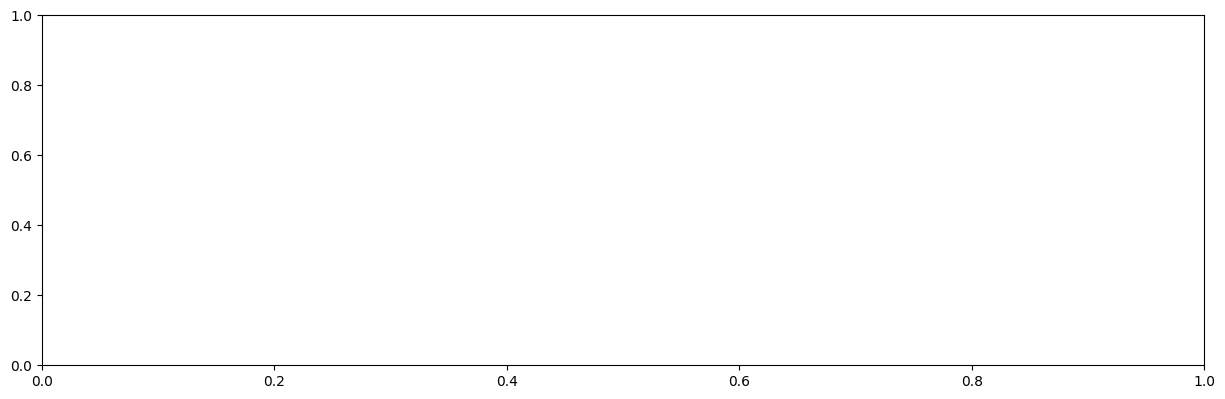

In [2]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

def load_data(folder_path, filename='metadata.csv'):
    all_data = []
    for file in os.listdir(folder_path):
        if file.endswith('.csv'):
            df = pd.read_csv(os.path.join(folder_path, file))
            all_data.append(df)
    train_data = pd.concat(all_data, ignore_index=True)
    metadata = pd.read_csv(os.path.join('/content/drive/MyDrive/special_training/', filename))
    print("train_data.head()")
    print(train_data.head())

    print("train_data.columns")
    print(train_data.columns)

    print("metadata.head()")
    print(metadata.head())

    print("metadata.columns")
    print(metadata.columns)

    return train_data, metadata

def process_data(train_data, metadata):
    #merged_data = pd.merge(train_data, metadata, on='filename', how='left')

    merged_data = pd.merge(train_data, metadata, left_index=True, right_index=True, how='left')

    #merged_data['ExperimentID'] = merged_data['ExperimentID'].fillna(merged_data['New_ExperimentID'])
    #merged_data['New_ExperimentID'] = merged_data['New_ExperimentID'].fillna(merged_data['ExperimentID'])
    #merged_data['Timestamp'] = pd.to_datetime(merged_data['Timestamp'], errors='coerce')

    # Timestamp列がある場合のみ処理
    if 'Timestamp' in merged_data.columns:
        merged_data['Timestamp'] = pd.to_datetime(merged_data['Timestamp'], errors='coerce')

    # 簡単な欠損値処理
    for col in merged_data.columns:
        if merged_data[col].dtype == 'object':
            merged_data[col] = merged_data[col].fillna('Unknown')
        else:
            merged_data[col] = merged_data[col].fillna(merged_data[col].mean())

    return merged_data


def clean_data(data):
    # 'Unknown'をNaNに変換
    data['Re'] = pd.to_numeric(data['Re'].replace('Unknown', np.nan), errors='coerce')
    data['Rct'] = pd.to_numeric(data['Rct'].replace('Unknown', np.nan), errors='coerce')

    # 極端な外れ値を除去 (99パーセンタイル以上)
    data['Re'] = data['Re'][data['Re'] < data['Re'].quantile(0.99)]
    data['Rct'] = data['Rct'][data['Rct'] < data['Rct'].quantile(0.99)]

    return data

    impedance_data = clean_data(impedance_data)


def analyze_internal_resistance(processed_data):
    print("Original data types:")
    print(processed_data.dtypes)
    print("\nSample data:")
    print(processed_data[['Time', 'Re', 'Rct']].head())


    # 'Unknown'をNaNに置き換え、その後float型に変換
    processed_data['Re'] = pd.to_numeric(processed_data['Re'].replace('Unknown', np.nan), errors='coerce')
    processed_data['Rct'] = pd.to_numeric(processed_data['Rct'].replace('Unknown', np.nan), errors='coerce')
    processed_data['Time'] = pd.to_numeric(processed_data['Time'], errors='coerce')

    print("\nData types after conversion:")
    print(processed_data.dtypes)

    impedance_data = processed_data[processed_data['type'] == 'impedance'].sort_values('Time')

    #plt.figure(figsize=(12, 10))
    plt.figure(figsize=(15, 10))

    # Reのプロット
    '''
    plt.subplot(2, 1, 1)
    sns.scatterplot(x='Time', y='Re', hue='battery_id', data=impedance_data, alpha=0.6)
    plt.title('Change in Re over Time')
    plt.ylabel('Re (Ohms)')
        '''
    plt.subplot(2, 1, 1)
    for battery in valid_data['battery_id'].unique():
        battery_data = valid_data[valid_data['battery_id'] == battery]
        normalized_time = (battery_data['Time'] - battery_data['Time'].min()) / (battery_data['Time'].max() - battery_data['Time'].min())
        plt.plot(normalized_time, battery_data['Re'], label=battery, alpha=0.5)

    plt.title('Change in Re over Normalized Time')
    plt.ylabel('Re (Ohms)')
    plt.yscale('log')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')


    # 線形回帰線の追加
    x = impedance_data['Time']
    y = impedance_data['Re']
    mask = ~np.isnan(x) & ~np.isnan(y)
    z = np.polyfit(x[mask], y[mask], 1)
    p = np.poly1d(z)
    plt.plot(x[mask], p(x[mask]), "r--", alpha=0.8)

    # Rctのプロット
    plt.subplot(2, 1, 2)
    sns.scatterplot(x='Time', y='Rct', hue='battery_id', data=impedance_data, alpha=0.6)
    plt.title('Change in Rct over Time')
    plt.xlabel('Time')
    plt.ylabel('Rct (Ohms)')

    # 線形回帰線の追加
    y = impedance_data['Rct']
    mask = ~np.isnan(x) & ~np.isnan(y)
    z = np.polyfit(x[mask], y[mask], 1)
    p = np.poly1d(z)
    plt.plot(x[mask], p(x[mask]), "r--", alpha=0.8)

    plt.tight_layout()
    plt.show()

    # 変化率の計算
    initial_re = impedance_data.groupby('battery_id')['Re'].first().mean()
    initial_rct = impedance_data.groupby('battery_id')['Rct'].first().mean()
    final_re = impedance_data.groupby('battery_id')['Re'].last().mean()
    final_rct = impedance_data.groupby('battery_id')['Rct'].last().mean()

    re_change_rate = (final_re - initial_re) / initial_re * 100
    rct_change_rate = (final_rct - initial_rct) / initial_rct * 100

    print(f"Average Re change rate: {re_change_rate:.2f}%")
    print(f"Average Rct change rate: {rct_change_rate:.2f}%")

def main():
    data_folder = '/content/drive/MyDrive/special_training/data/'
    train_data, metadata = load_data(data_folder)
    processed_data = process_data(train_data, metadata)

    print("処理後のデータ形状:", processed_data.shape)
    print("\n最初の数行:")
    print(processed_data.head())
    print("\n欠損値の数:")
    print(processed_data.isnull().sum())

    # ここで analyze_internal_resistance() を呼び出す
    analyze_internal_resistance(processed_data)

if __name__ == "__main__":
    main()

In [ ]:
'''
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

def analyze_internal_resistance(processed_data):
    print("Original data types:")
    print(processed_data.dtypes)
    print("\nSample data:")
    print(processed_data[['Time', 'Re', 'Rct']].head())


    # 'Unknown'をNaNに置き換え、その後float型に変換
    processed_data['Re'] = pd.to_numeric(processed_data['Re'].replace('Unknown', np.nan), errors='coerce')
    processed_data['Rct'] = pd.to_numeric(processed_data['Rct'].replace('Unknown', np.nan), errors='coerce')
    processed_data['Time'] = pd.to_numeric(processed_data['Time'], errors='coerce')

    print("\nData types after conversion:")
    print(processed_data.dtypes)

    impedance_data = processed_data[processed_data['type'] == 'impedance'].sort_values('Time')

    plt.figure(figsize=(12, 10))

    # Reのプロット
    plt.subplot(2, 1, 1)
    sns.scatterplot(x='Time', y='Re', hue='battery_id', data=impedance_data, alpha=0.6)
    plt.title('Change in Re over Time')
    plt.ylabel('Re (Ohms)')

    # 線形回帰線の追加
    x = impedance_data['Time']
    y = impedance_data['Re']
    mask = ~np.isnan(x) & ~np.isnan(y)
    z = np.polyfit(x[mask], y[mask], 1)
    p = np.poly1d(z)
    plt.plot(x[mask], p(x[mask]), "r--", alpha=0.8)

    # Rctのプロット
    plt.subplot(2, 1, 2)
    sns.scatterplot(x='Time', y='Rct', hue='battery_id', data=impedance_data, alpha=0.6)
    plt.title('Change in Rct over Time')
    plt.xlabel('Time')
    plt.ylabel('Rct (Ohms)')

    # 線形回帰線の追加
    y = impedance_data['Rct']
    mask = ~np.isnan(x) & ~np.isnan(y)
    z = np.polyfit(x[mask], y[mask], 1)
    p = np.poly1d(z)
    plt.plot(x[mask], p(x[mask]), "r--", alpha=0.8)

    plt.tight_layout()
    plt.show()

    # 変化率の計算
    initial_re = impedance_data.groupby('battery_id')['Re'].first().mean()
    initial_rct = impedance_data.groupby('battery_id')['Rct'].first().mean()
    final_re = impedance_data.groupby('battery_id')['Re'].last().mean()
    final_rct = impedance_data.groupby('battery_id')['Rct'].last().mean()

    re_change_rate = (final_re - initial_re) / initial_re * 100
    rct_change_rate = (final_rct - initial_rct) / initial_rct * 100

    print(f"Average Re change rate: {re_change_rate:.2f}%")
    print(f"Average Rct change rate: {rct_change_rate:.2f}%")

# 処理済みデータを使用
analyze_internal_resistance(processed_data)
'''

In [ ]:
'''
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def analyze_internal_resistance(processed_data):

    print("Time column data type:", processed_data['Time'].dtype)
    print("Time column head:", processed_data['Time'].head())
    impedance_data = processed_data[processed_data['type'] == 'impedance'].sort_values('Time')

    plt.figure(figsize=(12, 10))

    # Reのプロット
    plt.subplot(2, 1, 1)
    sns.scatterplot(x='Time', y='Re', hue='battery_id', data=impedance_data, alpha=0.6)
    plt.title('Change in Re over Time')
    plt.ylabel('Re (Ohms)')

    # 線形回帰線の追加
    x = impedance_data['Time']
    y = impedance_data['Re']
    z = np.polyfit(x, y, 1)
    p = np.poly1d(z)
    plt.plot(x, p(x), "r--", alpha=0.8)

    # Rctのプロット
    plt.subplot(2, 1, 2)
    sns.scatterplot(x='Time', y='Rct', hue='battery_id', data=impedance_data, alpha=0.6)
    plt.title('Change in Rct over Time')
    plt.xlabel('Time')
    plt.ylabel('Rct (Ohms)')

    # 線形回帰線の追加
    y = impedance_data['Rct']
    z = np.polyfit(x, y, 1)
    p = np.poly1d(z)
    plt.plot(x, p(x), "r--", alpha=0.8)

    plt.tight_layout()
    plt.show()

    # 変化率の計算
    initial_re = impedance_data.groupby('battery_id')['Re'].first().mean()
    initial_rct = impedance_data.groupby('battery_id')['Rct'].first().mean()
    final_re = impedance_data.groupby('battery_id')['Re'].last().mean()
    final_rct = impedance_data.groupby('battery_id')['Rct'].last().mean()

    re_change_rate = (final_re - initial_re) / initial_re * 100
    rct_change_rate = (final_rct - initial_rct) / initial_rct * 100

    print(f"Average Re change rate: {re_change_rate:.2f}%")
    print(f"Average Rct change rate: {rct_change_rate:.2f}%")

# 処理済みデータを使用
analyze_internal_resistance(processed_data)
'''